# Week 6 Benchmark Notebook: Amharic Speech-to-Speech Cascade (ASR, LLM, TTS)

This notebook benchmarks every candidate model from the Week 6 comparison and produces the measurements the assignment asks for. The primary metric is **End-to-End Time to First Audio (TTFA)**, the time from the end of the user's speech to the start of the first valid response audio. Quality is measured as a constraint.

| Stage | Candidates |
|---|---|
| ASR | `snapwre/hohe-asr-amharic`, `badrex/Ethio-ASR-amharic`, `waxal-benchmarking/mms-300m-waxal-amh` |
| LLM | `CohereLabs/tiny-aya-earth`, `google/gemma-3-4b-it` |
| TTS | `Lab-et/omnivoice-amharic` (step sweep), `facebook/mms-tts-amh` |

**Metrics collected**

| Stage | Latency metrics | Quality metrics | Resource metrics |
|---|---|---|---|
| ASR | per-clip latency (preprocess, forward, decode), real-time factor (RTF), time to useful output, cold-start call, length scaling | WER and CER overall and per condition (clean, noisy, phone 8 kHz, fast, names, numbers, mixed) | load time, peak VRAM, GPU utilization |
| LLM | time to first token (prefill), time to first clause, total generation time, decode tokens/s, tokens per reply | Belebele Amharic accuracy (comprehension), Amharic script ratio, reply length, digit leakage, sanity check for NaN or inf, ASR-error robustness pairs, human rating sheet for relevance and refusals, tokenizer efficiency | load time, peak VRAM, GPU utilization |
| TTS | time to first playable audio (full sentence and first clause), total generation latency, RTF, cold-start call | round-trip CER and WER through ASR, saved audio, blind listening sheet | load time, peak VRAM, GPU utilization |
| Pipeline | composed serial TTFA for every model combination, plus a measured end-to-end baseline run | | peak VRAM with all three models resident |

**Before you run**
1. Use a GPU runtime (the comparison assumes a T4). Record the GPU: results from different GPUs are not comparable.
2. Accept the gated licenses on Hugging Face for `CohereLabs/tiny-aya-earth` and `google/gemma-3-4b-it`, then log in when asked in Section 1.
3. Test data (Section 4). The notebook downloads the public FLEURS Amharic test split by default (ASR clips and TTS input sentences) and Belebele Amharic for the LLM comprehension check.
4. Every model is loaded, benchmarked and unloaded in turn so that one T4 is enough. Nothing here streams: for non-streaming models, time to first audio for a chunk equals its full synthesis time.

**Honest limits.** Latency depends on the GPU, driver and library versions, which are logged in the results file. Quality numbers are only as representative as the clips you feed in. Relevance and naturalness need human raters, so the notebook exports rating sheets instead of pretending to score them automatically.

## 1. Setup

In [1]:
%%capture
!pip install -q --upgrade transformers accelerate huggingface_hub jiwer soundfile librosa pandas matplotlib nvidia-ml-py datasets
!pip install -q uroman omnivoice

In [2]:
# Optional: KenLM is only needed for the hohe 5-gram language model timing in Section 5.
# The install can take a few minutes. Skip it if you do not need that measurement.
INSTALL_KENLM = False
if INSTALL_KENLM:
    !pip install -q pyctcdecode https://github.com/kpu/kenlm/archive/master.zip

In [3]:
import os, gc, io, re, json, time, math, random, shutil, threading, unicodedata, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch, soundfile as sf, librosa
import matplotlib.pyplot as plt
import transformers
from IPython.display import Audio, display

warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu"
print("Device:", DEVICE, "|", GPU_NAME)
if DEVICE == "cpu":
    print("WARNING: no GPU found. Latency numbers will not reflect the target hardware.")

# Gated models (tiny-aya-earth, gemma-3-4b-it) need a Hugging Face login.
from huggingface_hub import login
tok = os.environ.get("HF_TOKEN")
if tok:
    login(token=tok)
else:
    from huggingface_hub import notebook_login
    notebook_login()

Device: cuda | Tesla T4


## 2. Configuration

In [4]:
ASR_MODELS = {
    "hohe-asr-amharic":   "snapwre/hohe-asr-amharic",
    "Ethio-ASR-amharic":  "badrex/Ethio-ASR-amharic",
    "waxal-mms-300m-amh": "waxal-benchmarking/mms-300m-waxal-amh",
}
LLM_MODELS = {
    "tiny-aya-earth": "CohereLabs/tiny-aya-earth",
    "gemma-3-4b-it":  "google/gemma-3-4b-it",
}
TTS_MODELS = {
    "omnivoice-amharic": "Lab-et/omnivoice-amharic",
    "mms-tts-amh":       "facebook/mms-tts-amh",
}

# Precision. The T4 has no native bf16, so fp16 is used for the large models.
ASR_DTYPE = torch.float16
LLM_DTYPE = torch.float16
MMS_DTYPE = torch.float32          # VITS is small; fp32 avoids fp16 instability
OMNI_DTYPE = torch.float16

# OmniVoice sweep: (num_step, guidance_scale). 16 steps is the working default from the report.
OMNI_CONFIGS = [(8, 2.0), (16, 2.0), (32, 2.0)]

# Measurement settings
SEED = 42
N_WARMUP = 3            # untimed warm-up calls per model (a separate cold-start call is also recorded)
N_REPEATS = 1           # repeat each item and take the median latency (raise to 3 for stabler numbers)
MAX_NEW_TOKENS = 80     # cap on LLM reply length
VAD_HANGOVER_MS = 400   # assumed end-of-speech detection delay used when composing TTFA (report range: 300-500)

# ASR test-set options
MAKE_ASR_VARIANTS = True       # derive noisy (SNR 10 dB), phone (8 kHz) and fast (1.25x) versions of clean clips
MAX_ASR_CLIPS = None           # set an int to limit clips while testing the notebook

# Paths
DATA_DIR = Path("data"); OUT_DIR = Path("results")
for p in [DATA_DIR/"asr"/"audio", DATA_DIR/"llm", DATA_DIR/"tts", OUT_DIR, OUT_DIR/"tts_samples"]:
    p.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

ENV = dict(gpu=GPU_NAME, torch=torch.__version__, transformers=transformers.__version__,
           asr_dtype=str(ASR_DTYPE), llm_dtype=str(LLM_DTYPE), mms_dtype=str(MMS_DTYPE),
           omni_dtype=str(OMNI_DTYPE), seed=SEED, n_repeats=N_REPEATS, vad_ms=VAD_HANGOVER_MS)
print(json.dumps(ENV, indent=2))

{
  "gpu": "Tesla T4",
  "torch": "2.11.0+cu128",
  "transformers": "5.17.0",
  "asr_dtype": "torch.float16",
  "llm_dtype": "torch.float16",
  "mms_dtype": "torch.float32",
  "omni_dtype": "torch.float16",
  "seed": 42,
  "n_repeats": 1,
  "vad_ms": 400
}


## 3. Utilities: timing, GPU monitoring, text normalization, metrics

In [5]:
def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

def reset_peak():
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()

def peak_vram_mb():
    return torch.cuda.max_memory_allocated() / 2**20 if DEVICE == "cuda" else float("nan")

def free_gpu():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

def dtype_kw(dt):
    """transformers renamed torch_dtype to dtype around 4.56."""
    from packaging import version
    key = "dtype" if version.parse(transformers.__version__.split("+")[0]) >= version.parse("4.56.0") else "torch_dtype"
    return {key: dt}

def q(a, p):
    a = [x for x in a if x is not None and not (isinstance(x, float) and math.isnan(x))]
    return float(np.percentile(a, p)) if len(a) else float("nan")

class GPUMonitor:
    """Samples GPU utilization and used memory in a background thread (NVML)."""
    def __init__(self, interval=0.05):
        self.interval, self.samples, self.ok = interval, [], False
        self._stop = threading.Event()
        try:
            import pynvml
            pynvml.nvmlInit()
            self.h = pynvml.nvmlDeviceGetHandleByIndex(0); self.nv = pynvml; self.ok = DEVICE == "cuda"
        except Exception:
            self.ok = False
    def _run(self):
        while not self._stop.is_set():
            try:
                u = self.nv.nvmlDeviceGetUtilizationRates(self.h).gpu
                m = self.nv.nvmlDeviceGetMemoryInfo(self.h).used / 2**20
                self.samples.append((u, m))
            except Exception:
                break
            time.sleep(self.interval)
    def __enter__(self):
        if self.ok:
            self._t = threading.Thread(target=self._run, daemon=True); self._t.start()
        return self
    def __exit__(self, *a):
        self._stop.set()
        if self.ok: self._t.join(timeout=1)
    def summary(self):
        if not self.samples:
            return dict(gpu_util_mean=float("nan"), gpu_util_max=float("nan"), gpu_mem_used_peak_mb=float("nan"))
        u = [s[0] for s in self.samples]; m = [s[1] for s in self.samples]
        return dict(gpu_util_mean=float(np.mean(u)), gpu_util_max=float(np.max(u)), gpu_mem_used_peak_mb=float(np.max(m)))

# ---------- Amharic text normalization (identical for every model, as the report requires) ----------
_FOLD = {}
def _fold(src, dst, n=8):
    for i in range(n):
        _FOLD[chr(src + i)] = chr(dst + i)
# Ge'ez homophone folding: ሐ ኀ -> ሀ, ሠ -> ሰ, ዐ -> አ, ፀ -> ጸ (all vowel orders)
_fold(0x1210, 0x1200); _fold(0x1280, 0x1200); _fold(0x1220, 0x1230); _fold(0x12D0, 0x12A0); _fold(0x1340, 0x1338)

def normalize_am(t):
    t = unicodedata.normalize("NFC", str(t))
    t = re.sub(r"\[[A-Za-z]{2,4}\]", " ", t)          # strips hohe's [AMH] tag
    t = t.lower()
    t = "".join(_FOLD.get(c, c) for c in t)
    t = re.sub(r"[^\w\s]|_", " ", t)                  # drops Latin and Ethiopic punctuation
    return re.sub(r"\s+", " ", t).strip()

import jiwer
def wer_cer(refs, hyps):
    pairs = [(normalize_am(r), normalize_am(h)) for r, h in zip(refs, hyps) if normalize_am(r)]
    if not pairs: return float("nan"), float("nan")
    R, H = [p[0] for p in pairs], [p[1] for p in pairs]
    return jiwer.wer(R, H), jiwer.cer(R, H)

# ---------- Clause handling (used by the LLM and TTS benchmarks) ----------
CLAUSE_MARKS = set("።፧፤፣!?,;")
MIN_CLAUSE_CHARS = 8
def find_first_clause_end(text):
    for i, ch in enumerate(text):
        if ch in CLAUSE_MARKS and i + 1 >= MIN_CLAUSE_CHARS:
            return i + 1
    return None
def first_clause_text(text):
    e = find_first_clause_end(text)
    return text[:e].strip() if e else text.strip()

def ethiopic_ratio(text):
    letters = [c for c in text if c.isalpha()]
    return sum(0x1200 <= ord(c) <= 0x139F for c in letters) / len(letters) if letters else 0.0

# quick self-test
assert normalize_am("[AMH] ሰላም፣ እንዴት ነህ?") == "ሰላም እንዴት ነህ"
assert first_clause_text("ሰላም፣ እንዴት ነህ?") in ("ሰላም፣ እንዴት ነህ?", "ሰላም፣")
print("utilities ready")

utilities ready


## 4. Test data

Four datasets drive the benchmark.

**ASR: FLEURS `am_et` (default) plus your own clips.** FLEURS (Google, CC-BY-4.0) is read speech in the standard test split and is the common ground for comparing the three models. Of the datasets checked, none of the model cards list FLEURS as training data, which is not proof that a model has never seen it. Whatever the cards say, keep the WAXAL and BDU test splits out of the head-to-head, because at least two of the models were trained on those corpora. FLEURS is read speech, so expect it to look easier than real conversation.

**TTS: FLEURS transcripts plus the starter sentences.** FLEURS sentences are added as input text (category `fleurs`). They come from Wikipedia-derived material, so they include numbers and proper names. Round-trip CER through ASR needs no reference audio. The hand-written starter sentences stay in because they cover names, dates and code-switching, which FLEURS does not.

**LLM: Belebele `amh_Ethi` plus team prompts.** Belebele is a multiple-choice reading-comprehension set with Amharic questions built on FLORES-200 passages (the same source text as FLEURS). It measures Amharic understanding with an automatic score. It does not measure spoken-reply quality, so the conversational prompts in `data/llm/prompts.csv` (`id,category,user_text`) and the rating sheet remain necessary.

Starter prompt and sentence files are written on first run if missing. They are short on purpose. Replace them with about 30 conversational prompts and about 100 sentences before drawing conclusions.

In [6]:
# ---------- Starter LLM prompts (replace or extend) ----------
if not (DATA_DIR/"llm"/"prompts.csv").exists():
    pd.DataFrame([
        ("p01","greeting","ሰላም፣ እንዴት ነህ?"),
        ("p02","factual","የኢትዮጵያ ዋና ከተማ ምንድን ናት?"),
        ("p03","weather","ዛሬ በአዲስ አበባ የአየር ሁኔታ እንዴት ነው?"),
        ("p04","name","ስሜ አበበ ከበደ ይባላል፣ ከጎንደር ነው የመጣሁት። ስለ ከተማዬ ንገረኝ።"),
        ("p05","place","ከባህር ዳር ወደ ላሊበላ ስንት ሰዓት ይፈጃል?"),
        ("p06","transport","ወደ ሀዋሳ የሚሄደው አውቶቡስ ስንት ሰዓት ይነሳል?"),
        ("p07","how_to","እንዴት ቡና ማፍላት እችላለሁ?"),
        ("p08","mixed","ኮምፒውተሬ ላይ ዊንዶውስ አፕዴት ማድረግ አለብኝ፣ እንዴት ልጀምር?"),
        ("p09","mixed","ስልኬ ላይ ዋይፋይ አይሰራም፣ ምን ላድርግ?"),
        ("p10","noisy_asr","ዛሬ አዲስ አበባ የአየር ሁኔታ እንዴት"),
        ("p11","harmless_probe","በኩሽና ውስጥ ቢላዋን በደህና እንዴት መጠቀም እችላለሁ?"),
        ("p12","date","የኢትዮጵያ አዲስ ዓመት መቼ ነው የሚከበረው?"),
    ], columns=["id","category","user_text"]).to_csv(DATA_DIR/"llm"/"prompts.csv", index=False)

# ---------- Starter TTS sentences (replace or extend) ----------
if not (DATA_DIR/"tts"/"sentences.csv").exists():
    pd.DataFrame([
        ("s01","greeting","ሰላም፣ እንዴት ነህ? ዛሬ እንዴት አደርክ።"),
        ("s02","question","የኢትዮጵያ ዋና ከተማ ምንድን ናት? አዲስ አበባ ናት።"),
        ("s03","weather","ዛሬ በአዲስ አበባ የአየር ሁኔታ ደመናማ ነው፣ ምሽት ላይ ዝናብ ሊኖር ይችላል።"),
        ("s04","name","ስሜ አበበ ከበደ ይባላል፣ ከጎንደር ነው የመጣሁት።"),
        ("s05","place","ከባህር ዳር ወደ ላሊበላ ለመሄድ ስምንት ሰዓት ገደማ ይፈጃል።"),
        ("s06","number","ትኬቱ አምስት መቶ ሃያ ብር ነው።"),
        ("s07","date","ስብሰባው በመስከረም ሃያ አምስት ቀን ይካሄዳል።"),
        ("s08","transport","ወደ ሀዋሳ የሚሄደው አውቶቡስ ጠዋት ሁለት ሰዓት ላይ ይነሳል።"),
        ("s09","mixed","ኮምፒውተሬ ላይ ዊንዶውስ አፕዴት ማድረግ አለብኝ።"),
        ("s10","mixed","ስልኬ ላይ ዋይፋይ አይሰራም።"),
        ("s11","short","እሺ፣ ተረድቻለሁ።"),
        ("s12","long","የኢትዮጵያ ቡና በዓለም ላይ ታዋቂ ነው፣ ምክንያቱም ቡና መጀመሪያ የተገኘው በካፋ ክልል ውስጥ ነው ተብሎ ይታመናል።"),
    ], columns=["id","category","text"]).to_csv(DATA_DIR/"tts"/"sentences.csv", index=False)

LLM_PROMPTS = pd.read_csv(DATA_DIR/"llm"/"prompts.csv")
TTS_SENTENCES = pd.read_csv(DATA_DIR/"tts"/"sentences.csv")
print(len(LLM_PROMPTS), "LLM prompts,", len(TTS_SENTENCES), "TTS sentences")

12 LLM prompts, 12 TTS sentences


In [7]:
# ---------- FLEURS am_et: default ASR test set and TTS input sentences ----------
# The files are downloaded straight from the dataset repo (data/am_et/<split>.tsv and
# data/am_et/audio/<split>.tar.gz), so this does not depend on the `datasets` script loader,
# which newer `datasets` versions no longer support.
USE_FLEURS = True
FLEURS_SPLIT = "test"
N_FLEURS_ASR = 100        # clips (random sample, fixed seed, several speakers)
N_FLEURS_TTS = 40         # distinct sentences used as TTS input
FLEURS_TTS_CHARS = (40, 220)   # keep sentence length in this range so outliers do not dominate timings
FLEURS_REPO = "google/fleurs"
fleurs_manifest = DATA_DIR/"asr"/"manifest_fleurs.csv"
own_manifest = DATA_DIR/"asr"/"manifest.csv"          # optional: your own labelled clips
FLEURS_SENTENCES = pd.DataFrame(columns=["id", "category", "text"])

def read_fleurs_tsv(split):
    """FLEURS TSV has no header. Columns: sentence id, file name, raw transcription, normalized
    transcription, phonemes, num_samples, gender."""
    import csv
    from huggingface_hub import hf_hub_download
    tsv = hf_hub_download(FLEURS_REPO, f"data/am_et/{split}.tsv", repo_type="dataset")
    rows = []
    with open(tsv, encoding="utf-8", newline="") as f:
        for r in csv.reader(f, delimiter="\t", quoting=csv.QUOTE_NONE):
            if len(r) >= 4:
                rows.append(dict(sent_id=r[0], file=r[1], raw=r[2], norm=r[3], gender=r[6] if len(r) > 6 else ""))
    return rows

def extract_fleurs_audio(split, wanted_files, out_dir):
    """Reads only the requested wav files out of the split's tar.gz and writes them as 16 kHz mono."""
    import tarfile
    from huggingface_hub import hf_hub_download
    tar_path = hf_hub_download(FLEURS_REPO, f"data/am_et/audio/{split}.tar.gz", repo_type="dataset")
    left, written = set(wanted_files), {}
    with tarfile.open(tar_path, "r:gz") as tf:
        for m in tf:
            base = os.path.basename(m.name)
            if base in left and m.isfile():
                a, sr = sf.read(io.BytesIO(tf.extractfile(m).read()), dtype="float32")
                if a.ndim > 1: a = a.mean(1)
                if sr != 16000: a = librosa.resample(a, orig_sr=sr, target_sr=16000)
                p = out_dir / (Path(base).stem + ".wav")
                sf.write(p, a, 16000); written[base] = str(p); left.discard(base)
                if not left: break
    if left: print(f"  warning: {len(left)} requested files were not found in the archive")
    return written

def build_fleurs(split=FLEURS_SPLIT, n_asr=N_FLEURS_ASR, n_tts=N_FLEURS_TTS):
    rows = read_fleurs_tsv(split)
    rnd = random.Random(SEED)
    pick = rnd.sample(rows, min(n_asr, len(rows)))
    audio_dir = DATA_DIR/"asr"/"audio"/"fleurs"; audio_dir.mkdir(parents=True, exist_ok=True)
    got = extract_fleurs_audio(split, [r["file"] for r in pick], audio_dir)
    man = [(got[r["file"]], r["norm"] or r["raw"], "fleurs_clean") for r in pick if r["file"] in got]
    pd.DataFrame(man, columns=["audio_path", "text", "condition"]).to_csv(fleurs_manifest, index=False)
    # TTS sentences: distinct sentence ids, raw text (keeps punctuation for clause splitting)
    seen, cands = set(), []
    for r in rows:
        if r["sent_id"] in seen: continue
        seen.add(r["sent_id"])
        if FLEURS_TTS_CHARS[0] <= len(r["raw"]) <= FLEURS_TTS_CHARS[1]: cands.append(r)
    tts = rnd.sample(cands, min(n_tts, len(cands)))
    if len(cands) < n_tts:
        print(f"  note: only {len(cands)} FLEURS sentences fit the length filter {FLEURS_TTS_CHARS}; widen FLEURS_TTS_CHARS for more")
    sent = pd.DataFrame([(f"fl{r['sent_id']}", "fleurs", r["raw"]) for r in tts], columns=["id", "category", "text"])
    sent.to_csv(DATA_DIR/"tts"/"fleurs_sentences.csv", index=False)
    return len(man), sent

if USE_FLEURS:
    try:
        if fleurs_manifest.exists() and (DATA_DIR/"tts"/"fleurs_sentences.csv").exists():
            print("FLEURS files already present, reusing them.")
            FLEURS_SENTENCES = pd.read_csv(DATA_DIR/"tts"/"fleurs_sentences.csv")
        else:
            n, FLEURS_SENTENCES = build_fleurs()
            print(f"FLEURS {FLEURS_SPLIT}: wrote {n} ASR clips and {len(FLEURS_SENTENCES)} TTS sentences")
    except Exception as e:
        print("FLEURS download failed:", repr(e)[:400])
        print("Fallbacks: (1) `pip install \"datasets<4\"` and load with trust_remote_code=True; "
              "(2) download data/am_et/test.tsv and data/am_et/audio/test.tar.gz from the dataset page and "
              "write data/asr/manifest_fleurs.csv (audio_path,text,condition=fleurs_clean) yourself.")

ASR_MANIFESTS = [p for p in (own_manifest, fleurs_manifest) if p.exists()]
print("ASR manifests:", [str(p) for p in ASR_MANIFESTS])

test.tsv:   0%|          | 0.00/392k [00:00<?, ?B/s]

data/am_et/audio/test.tar.gz: reconstructing file:   0%|          |  0.00B /  278MB            

data/am_et/audio/test.tar.gz: downloading bytes:           |  0.00B            

FLEURS test: wrote 100 ASR clips and 40 TTS sentences
ASR manifests: ['data/asr/manifest_fleurs.csv']


In [8]:
# Add the FLEURS sentences to the TTS set. The hand-written starter sentences stay (names, dates, mixed text).
if len(FLEURS_SENTENCES):
    TTS_SENTENCES = pd.concat([TTS_SENTENCES[TTS_SENTENCES.category != "fleurs"], FLEURS_SENTENCES], ignore_index=True)
print(len(TTS_SENTENCES), "TTS sentences:", TTS_SENTENCES.category.value_counts().to_dict())

52 TTS sentences: {'fleurs': 40, 'mixed': 2, 'greeting': 1, 'question': 1, 'weather': 1, 'name': 1, 'place': 1, 'number': 1, 'date': 1, 'transport': 1, 'short': 1, 'long': 1}


In [9]:
def add_noise(a, snr_db, rng):
    p = np.mean(a ** 2) + 1e-12
    noise = rng.standard_normal(len(a)) * np.sqrt(p / (10 ** (snr_db / 10)))
    return (a + noise).astype("float32")

def telephone(a):
    lo = librosa.resample(a, orig_sr=16000, target_sr=8000)
    return librosa.resample(lo, orig_sr=8000, target_sr=16000).astype("float32")

def build_asr_items(manifest_csvs, make_variants=True, max_clips=None):
    df = pd.concat([pd.read_csv(p) for p in manifest_csvs], ignore_index=True)
    if "condition" not in df.columns: df["condition"] = "clean"
    if max_clips: df = df.head(max_clips)
    rng = np.random.default_rng(SEED)
    items = []
    for i, r in enumerate(df.itertuples()):
        a, _ = librosa.load(r.audio_path, sr=16000, mono=True)
        items.append(dict(id=f"{i:04d}", condition=r.condition, audio=a, ref=r.text))
        if make_variants and str(r.condition).endswith("clean"):
            pre = str(r.condition)[:-len("clean")]          # "" for clean, "fleurs_" for fleurs_clean
            items.append(dict(id=f"{i:04d}n", condition=pre + "noisy_snr10", audio=add_noise(a, 10, rng), ref=r.text))
            items.append(dict(id=f"{i:04d}p", condition=pre + "phone_8k", audio=telephone(a), ref=r.text))
            items.append(dict(id=f"{i:04d}f", condition=pre + "fast_1.25x", audio=librosa.effects.time_stretch(a, rate=1.25), ref=r.text))
    return items

ASR_ITEMS = []
if ASR_MANIFESTS:
    ASR_ITEMS = build_asr_items(ASR_MANIFESTS, MAKE_ASR_VARIANTS, MAX_ASR_CLIPS)
    print(len(ASR_ITEMS), "ASR items;", pd.Series([x["condition"] for x in ASR_ITEMS]).value_counts().to_dict())
    print("total audio: %.1f min" % (sum(len(x["audio"]) for x in ASR_ITEMS) / 16000 / 60))
else:
    print("No ASR data yet. Enable USE_FLEURS in Section 4 ")

400 ASR items; {'fleurs_clean': 100, 'fleurs_noisy_snr10': 100, 'fleurs_phone_8k': 100, 'fleurs_fast_1.25x': 100}
total audio: 70.3 min


## 5. Category 1: ASR benchmark

Each clip is timed in three parts: preprocessing (feature extraction on CPU), the forward pass on the GPU, and greedy CTC decoding. All three count toward the delay the user experiences. None of these models streams, so **time to useful output equals total latency measured from the end of speech**. VAD delay is added later, in the pipeline composition.

RTF is total latency divided by audio duration. WER and CER use the same normalization for every model (Section 3), which is required for the numbers to be comparable. The first call after loading is recorded separately as the cold-start cost.

In [10]:
class AsrRunner:
    def __init__(self, name, repo, dtype=ASR_DTYPE):
        self.name, self.repo, self.dtype = name, repo, dtype
    def load(self):
        from transformers import AutoProcessor, AutoModelForCTC
        reset_peak(); t = time.perf_counter()
        self.proc = AutoProcessor.from_pretrained(self.repo)
        self.model = AutoModelForCTC.from_pretrained(self.repo, **dtype_kw(self.dtype)).to(DEVICE).eval()
        sync(); self.load_s = time.perf_counter() - t
        self.params_m = sum(p.numel() for p in self.model.parameters()) / 1e6
        self.vram_after_load_mb = torch.cuda.memory_allocated() / 2**20 if DEVICE == "cuda" else float("nan")
        return self
    def unload(self):
        del self.model, self.proc; free_gpu()
    def _prep(self, audio):
        x = self.proc(audio, sampling_rate=16000, return_tensors="pt")
        return {k: (v.to(DEVICE, dtype=self.dtype) if v.is_floating_point() else v.to(DEVICE)) for k, v in x.items()}
    @torch.inference_mode()
    def transcribe(self, audio, keep_logits=False):
        t0 = time.perf_counter()
        x = self._prep(audio); sync(); t1 = time.perf_counter()
        logits = self.model(**x).logits; sync(); t2 = time.perf_counter()
        text = self.proc.batch_decode(logits.argmax(-1))[0]; t3 = time.perf_counter()
        tm = dict(prep_ms=(t1-t0)*1e3, fwd_ms=(t2-t1)*1e3, dec_ms=(t3-t2)*1e3, total_ms=(t3-t0)*1e3)
        return text, tm, (logits[0].float().cpu().numpy() if keep_logits else None)

def bench_asr(runner, items, n_warmup=N_WARMUP, n_repeats=N_REPEATS):
    runner.load()
    cold = runner.transcribe(items[0]["audio"])[1]["total_ms"]
    for it in items[:n_warmup]: runner.transcribe(it["audio"])
    reset_peak(); rows = []
    with GPUMonitor() as mon:
        for it in items:
            lats, text = [], None
            for _ in range(n_repeats):
                text_i, tm, _ = runner.transcribe(it["audio"]); lats.append(tm)
                text = text if text is not None else text_i
            dur = len(it["audio"]) / 16000
            med = {k: float(np.median([l[k] for l in lats])) for k in lats[0]}
            rows.append(dict(model=runner.name, id=it["id"], condition=it["condition"], dur_s=dur,
                             ref=it["ref"], hyp=text, rtf=med["total_ms"] / 1e3 / dur, **med))
    df = pd.DataFrame(rows)
    # length scaling on the first clean clip
    base = items[0]["audio"]; scal = []
    for s in (1, 3, 5, 10, 20):
        n = int(s * 16000); a = np.tile(base, int(np.ceil(n / len(base))))[:n]
        lat = float(np.median([runner.transcribe(a)[1]["total_ms"] for _ in range(3)]))
        scal.append(dict(model=runner.name, audio_s=s, latency_ms=lat, rtf=lat / 1e3 / s))
    w, c = wer_cer(df["ref"], df["hyp"])
    meta = dict(model=runner.name, params_m=runner.params_m, n_items=len(df), wer=w, cer=c,
                lat_median_ms=df.total_ms.median(), lat_p90_ms=q(df.total_ms, 90),
                prep_median_ms=df.prep_ms.median(), fwd_median_ms=df.fwd_ms.median(), dec_median_ms=df.dec_ms.median(),
                rtf_median=df.rtf.median(), rtf_p90=q(df.rtf, 90), cold_first_call_ms=cold,
                load_s=runner.load_s, vram_after_load_mb=runner.vram_after_load_mb, peak_vram_mb=peak_vram_mb(),
                **mon.summary())
    runner.unload()
    return df, meta, pd.DataFrame(scal)

ASR_CLIPS, ASR_META, ASR_SCALING = [], [], []
for name, repo in ASR_MODELS.items():
    if not ASR_ITEMS: break
    print("=== ASR:", name)
    try:
        df, meta, scal = bench_asr(AsrRunner(name, repo), ASR_ITEMS)
        ASR_CLIPS.append(df); ASR_META.append(meta); ASR_SCALING.append(scal)
        print("  WER %.3f  CER %.3f  median %.0f ms  RTF %.3f" % (meta["wer"], meta["cer"], meta["lat_median_ms"], meta["rtf_median"]))
    except Exception as e:
        print("  FAILED:", repr(e)[:400]); free_gpu()

=== ASR: hohe-asr-amharic


preprocessor_config.json:   0%|          | 0.00/275 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.86k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/5.60k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/32.0 [00:00<?, ?B/s]

... (21 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

  WER 0.485  CER 0.230  median 64 ms  RTF 0.006


In [11]:
if ASR_META:
    ASR_SUMMARY = pd.DataFrame(ASR_META).set_index("model")
    ASR_ALL = pd.concat(ASR_CLIPS, ignore_index=True)
    ASR_BY_COND = (ASR_ALL.groupby(["condition", "model"])
        .apply(lambda g: pd.Series(dict(n=len(g), WER=wer_cer(g.ref, g.hyp)[0], CER=wer_cer(g.ref, g.hyp)[1],
                                        lat_median_ms=g.total_ms.median(), lat_p90_ms=q(g.total_ms, 90), rtf_median=g.rtf.median())))
        .reset_index())
    display(ASR_SUMMARY.round(3))
    display(ASR_BY_COND.round(3))
    display(pd.concat(ASR_SCALING).round(2))

,params_m,n_items,wer,cer,lat_median_ms,lat_p90_ms,prep_median_ms,fwd_median_ms,dec_median_ms,rtf_median,rtf_p90,cold_first_call_ms,load_s,vram_after_load_mb,peak_vram_mb,gpu_util_mean,gpu_util_max,gpu_mem_used_peak_mb
model,,,,,,,,,,,,,,,,,,
hohe-asr-amharic,606.105,400,0.277,0.116,160.748,464.356,46.342,105.787,0.604,0.013,0.054,2239.014,35.234,1156.062,1522.195,26.620,100.0,2514.188
Ethio-ASR-amharic,606.099,400,0.266,0.102,126.564,212.627,51.467,74.601,0.643,0.012,0.020,261.203,62.109,1165.646,1522.984,47.923,99.0,2508.188
waxal-mms-300m-amh,315.812,400,0.485,0.230,64.006,82.597,1.700,61.807,0.546,0.006,0.008,624.347,29.379,611.959,949.889,87.954,97.0,2144.188


,condition,model,n,WER,CER,lat_median_ms,lat_p90_ms,rtf_median
0,fleurs_clean,Ethio-ASR-amharic,100.0,0.172,0.051,131.568,221.565,0.012
1,fleurs_clean,hohe-asr-amharic,100.0,0.165,0.060,402.635,594.622,0.037
2,fleurs_clean,waxal-mms-300m-amh,100.0,0.275,0.086,68.651,80.551,0.006
3,fleurs_fast_1.25x,Ethio-ASR-amharic,100.0,0.475,0.226,104.674,187.768,0.012
4,fleurs_fast_1.25x,hohe-asr-amharic,100.0,0.536,0.259,399.003,576.337,0.047
5,fleurs_fast_1.25x,waxal-mms-300m-amh,100.0,0.883,0.554,64.633,78.926,0.008
6,fleurs_noisy_snr10,Ethio-ASR-amharic,100.0,0.242,0.079,133.817,211.565,0.012
7,fleurs_noisy_snr10,hohe-asr-amharic,100.0,0.236,0.085,117.854,197.844,0.011
8,fleurs_noisy_snr10,waxal-mms-300m-amh,100.0,0.478,0.185,62.983,85.085,0.006
9,fleurs_phone_8k,Ethio-ASR-amharic,100.0,0.177,0.050,134.946,206.723,0.012


,model,audio_s,latency_ms,rtf
0,hohe-asr-amharic,1,52.19,0.05
1,hohe-asr-amharic,3,66.29,0.02
2,hohe-asr-amharic,5,74.80,0.01
3,hohe-asr-amharic,10,109.23,0.01
4,hohe-asr-amharic,20,251.90,0.01
0,Ethio-ASR-amharic,1,52.62,0.05
1,Ethio-ASR-amharic,3,63.29,0.02
2,Ethio-ASR-amharic,5,75.34,0.02
3,Ethio-ASR-amharic,10,120.43,0.01
4,Ethio-ASR-amharic,20,275.84,0.01


In [12]:
# Optional: hohe with the shipped 5-gram LM. Measures the extra decode time and WER gain separately,
# so the LM can be enabled only if the added time is small (the report suggests about 30 ms as a threshold).
RUN_HOHE_LM = False
if RUN_HOHE_LM and ASR_ITEMS:
    try:
        from huggingface_hub import hf_hub_download
        from pyctcdecode import build_ctcdecoder
        repo = ASR_MODELS["hohe-asr-amharic"]
        cfg = json.load(open(hf_hub_download(repo, "lm/decoder.json")))
        lm_bin = hf_hub_download(repo, "lm/am-5gram.bin")
        r = AsrRunner("hohe-asr-amharic", repo).load()
        vocab = r.proc.tokenizer.get_vocab()
        labels = [""] * (max(vocab.values()) + 1)
        for tk, i in vocab.items():
            labels[i] = " " if tk == "|" else ("" if i == r.proc.tokenizer.pad_token_id else tk)
        decoder = build_ctcdecoder(labels, lm_bin, alpha=cfg["alpha"], beta=cfg["beta"])
        refs, greedy_h, lm_h, lm_ms = [], [], [], []
        for it in ASR_ITEMS:
            text, tm, lg = r.transcribe(it["audio"], keep_logits=True)
            t = time.perf_counter(); h = decoder.decode(lg); lm_ms.append((time.perf_counter() - t) * 1e3)
            refs.append(it["ref"]); greedy_h.append(text); lm_h.append(h)
        gw, gc_ = wer_cer(refs, greedy_h); lw, lc = wer_cer(refs, lm_h)
        print("greedy WER %.3f CER %.3f | +LM WER %.3f CER %.3f | LM decode median %.1f ms, p90 %.1f ms"
              % (gw, gc_, lw, lc, np.median(lm_ms), q(lm_ms, 90)))
        r.unload()
    except Exception as e:
        print("LM timing failed (is KenLM installed? set INSTALL_KENLM=True and rerun Setup):", repr(e)[:300])

## 6. Category 2: LLM benchmark

Each prompt is answered with the same system prompt that forces one or two short spoken sentences in Amharic with numbers written as words. Decoding is greedy so runs are repeatable.

Timing points, all measured from the moment `generate()` is called:
- **Time to first token** is prefill plus the first decode step.
- **Time to first clause** is when the decoded text first contains a clause-ending mark after at least 8 characters. This is the number that matters for TTFA, because it is when the first speakable chunk can be sent to TTS.
- **Total generation time** and **decode tokens per second** cover the whole reply.

The clause check decodes the growing reply on each step, which adds a small CPU overhead of a few hundred microseconds per token. It is the same for every model.

Two checks that need care. **Gemma 3 in fp16** is reported to overflow on T4 GPUs, so a forward-pass sanity check flags NaN or inf logits and the latency numbers should be ignored if it fails. **Relevance and refusals** cannot be scored automatically, so a rating sheet is exported at the end of this section.

In [13]:
from transformers import StoppingCriteria, StoppingCriteriaList

SYSTEM_PROMPT = ("You are a voice assistant for Amharic speakers. Reply only in Amharic, in one or two short "
                 "spoken sentences of at most 25 words. Use plain conversational language. Do not use lists, "
                 "markdown, emojis or digits. Write all numbers as words.")

class StepTimer(StoppingCriteria):
    """Records a timestamp after every generated token and detects the first speakable clause."""
    def __init__(self, tok, prompt_len, stop_at_clause=False):
        self.tok, self.n0, self.stop_at_clause = tok, prompt_len, stop_at_clause
        self.times, self.clause_t, self.clause_step = [], None, None
    def __call__(self, input_ids, scores, **kw):
        sync(); now = time.perf_counter(); self.times.append(now)
        fire = False
        if self.clause_t is None:
            txt = self.tok.decode(input_ids[0, self.n0:], skip_special_tokens=True)
            if find_first_clause_end(txt) is not None:
                self.clause_t, self.clause_step = now, len(self.times); fire = self.stop_at_clause
        elif self.stop_at_clause:
            fire = True
        return torch.full((input_ids.shape[0],), fire, dtype=torch.bool, device=input_ids.device)

class LlmRunner:
    def __init__(self, name, repo, dtype=LLM_DTYPE):
        self.name, self.repo, self.dtype = name, repo, dtype
    def load(self):
        from transformers import AutoTokenizer, AutoModelForCausalLM
        reset_peak(); t = time.perf_counter()
        self.tok = AutoTokenizer.from_pretrained(self.repo)
        self.model = AutoModelForCausalLM.from_pretrained(self.repo, device_map={"": 0} if DEVICE == "cuda" else None,
                                                          **dtype_kw(self.dtype)).eval()
        sync(); self.load_s = time.perf_counter() - t
        self.params_b = sum(p.numel() for p in self.model.parameters()) / 1e9
        self.vram_after_load_mb = torch.cuda.memory_allocated() / 2**20 if DEVICE == "cuda" else float("nan")
        self.pad = self.tok.pad_token_id if self.tok.pad_token_id is not None else self.tok.eos_token_id
        return self
    def unload(self):
        del self.model, self.tok; free_gpu()
    def build(self, user_text):
        msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user_text}]
        try:
            enc = self.tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)
        except Exception:
            msgs = [{"role": "user", "content": SYSTEM_PROMPT + "\n\n" + user_text}]
            enc = self.tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)
        return {k: v.to(DEVICE) for k, v in enc.items()}
    @torch.inference_mode()
    def sanity(self):
        logits = self.model(**self.build("ሰላም")).logits
        return bool(torch.isfinite(logits).all())
    @torch.inference_mode()
    def reply(self, user_text, max_new_tokens=MAX_NEW_TOKENS, stop_at_clause=False):
        inp = self.build(user_text); n0 = inp["input_ids"].shape[1]
        st = StepTimer(self.tok, n0, stop_at_clause)
        sync(); t0 = time.perf_counter()
        out = self.model.generate(**inp, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=self.pad,
                                  stopping_criteria=StoppingCriteriaList([st]))
        sync(); t_end = time.perf_counter()
        text = self.tok.decode(out[0, n0:], skip_special_tokens=True).strip()
        n_new = len(st.times)
        ttft = (st.times[0] - t0) * 1e3 if st.times else float("nan")
        clause = ((st.clause_t or t_end) - t0) * 1e3
        tps = (n_new - 1) / (st.times[-1] - st.times[0]) if n_new > 1 and st.times[-1] > st.times[0] else float("nan")
        return dict(text=text, prompt_tokens=n0, new_tokens=n_new, ttft_ms=ttft, first_clause_ms=clause,
                    first_clause_tokens=st.clause_step or n_new, total_ms=(t_end - t0) * 1e3, decode_tps=tps,
                    clause_found=st.clause_t is not None)

def bench_llm(runner, prompts, n_warmup=N_WARMUP, n_repeats=N_REPEATS):
    runner.load()
    finite = runner.sanity()
    cold = runner.reply(prompts.user_text.iloc[0])["total_ms"]
    for t in prompts.user_text.iloc[:n_warmup]: runner.reply(t)
    reset_peak(); rows = []
    with GPUMonitor() as mon:
        for r in prompts.itertuples():
            runs = [runner.reply(r.user_text) for _ in range(n_repeats)]
            res = dict(runs[0])
            for k in ("ttft_ms", "first_clause_ms", "total_ms", "decode_tps"):
                res[k] = float(np.nanmedian([x[k] for x in runs]))
            res.update(model=runner.name, id=r.id, category=r.category, user_text=r.user_text,
                       ethiopic_ratio=ethiopic_ratio(res["text"]), has_digits=bool(re.search(r"\d", res["text"])),
                       n_words=len(res["text"].split()))
            rows.append(res)
    df = pd.DataFrame(rows)
    meta = dict(model=runner.name, params_b=runner.params_b, n_prompts=len(df), logits_finite=finite,
                ttft_median_ms=df.ttft_ms.median(), ttft_p90_ms=q(df.ttft_ms, 90),
                first_clause_median_ms=df.first_clause_ms.median(), first_clause_p90_ms=q(df.first_clause_ms, 90),
                total_median_ms=df.total_ms.median(), total_p90_ms=q(df.total_ms, 90),
                decode_tps_median=df.decode_tps.median(), new_tokens_median=df.new_tokens.median(),
                prompt_tokens_median=df.prompt_tokens.median(), words_median=df.n_words.median(),
                clause_found_rate=df.clause_found.mean(), amharic_script_ratio=df.ethiopic_ratio.mean(),
                digit_leak_rate=df.has_digits.mean(), cold_first_call_ms=cold, load_s=runner.load_s,
                vram_after_load_mb=runner.vram_after_load_mb, peak_vram_mb=peak_vram_mb(), **mon.summary())
    runner.unload()
    return df, meta

LLM_REPLIES, LLM_META = [], []
for name, repo in LLM_MODELS.items():
    print("=== LLM:", name)
    try:
        df, meta = bench_llm(LlmRunner(name, repo), LLM_PROMPTS)
        LLM_REPLIES.append(df); LLM_META.append(meta)
        print("  finite logits:", meta["logits_finite"], "| first clause median %.0f ms | %.1f tok/s"
              % (meta["first_clause_median_ms"], meta["decode_tps_median"]))
    except Exception as e:
        print("  FAILED:", repr(e)[:500]); free_gpu()

=== LLM: tiny-aya-earth


config.json:   0%|          | 0.00/1.96k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/8.17k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 21.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/567 [00:00<?, ?B/s]

... (14 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

  finite logits: False | first clause median 5735 ms | 14.0 tok/s


In [14]:
if LLM_META:
    LLM_SUMMARY = pd.DataFrame(LLM_META).set_index("model")
    LLM_ALL = pd.concat(LLM_REPLIES, ignore_index=True)
    display(LLM_SUMMARY.round(2).T)
    display(LLM_ALL[["model", "id", "category", "text", "new_tokens", "first_clause_ms", "total_ms"]].round(0).head(30))
    if (LLM_SUMMARY.logits_finite == False).any():
        print("WARNING: at least one model produced non-finite logits. Its latency numbers are not trustworthy.")

model,tiny-aya-earth,gemma-3-4b-it
params_b,3.35,4.3
n_prompts,12,12
logits_finite,True,False
ttft_median_ms,237.12,89.38
ttft_p90_ms,252.92,104.7
first_clause_median_ms,1041.95,5735.22
first_clause_p90_ms,1389.51,6151.02
total_median_ms,1901.98,5735.22
total_p90_ms,4017.78,6151.02
decode_tps_median,21.11,13.99


,model,id,category,text,new_tokens,first_clause_ms,total_ms
0,tiny-aya-earth,p01,greeting,ሰላም! እንዴት ነህ?,11,715.0,838.0
1,tiny-aya-earth,p02,factual,አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።,16,1050.0,1144.0
2,tiny-aya-earth,p03,weather,ዛሬ በአዲስ አበባ የአየር ሁኔታ ደረቅ እና ሙቀት ያለው ነው። ሙቀት በሰ...,38,1120.0,1945.0
3,tiny-aya-earth,p04,name,አበበ፣ ጎንደር የኢትዮጵያ ታሪካዊ ከተማ ናት፣ በሰሜን ምዕራብ አገር ውስ...,80,1034.0,3926.0
4,tiny-aya-earth,p05,place,ከባህር ዳር ወደ ላሊበላ በትራንስፖርት መኪና በሰዓት አስር ሰዓት ይፈጃል።,36,1768.0,1859.0
5,tiny-aya-earth,p06,transport,ወደ ሀዋሳ የሚሄደው አውቶቡስ በጠዋት ሰዓት ይነሳል።,28,1413.0,1505.0
6,tiny-aya-earth,p07,how_to,ቡናን ለማፍላት፣ ውሃን በቡና ማፍላት ማሽን ውስጥ አስገባ። ቡናን ወደ ማ...,65,695.0,4000.0
7,tiny-aya-earth,p08,mixed,"ዊንዶውስ አፕዴት ለማድረግ፣ ኮምፒውተሩን በ""Settings"" ውስጥ ይክፈቱ...",69,749.0,3422.0
8,tiny-aya-earth,p09,mixed,ስልክዎ ላይ ዋይፋይ ካልተሰራ፣ በመጀመሪያ ሽፋንዎን ያረጋግጡ። ከዚያ፣ ሽ...,80,849.0,4020.0
9,tiny-aya-earth,p10,noisy_asr,ዛሬ አዲስ አበባ በደስታ ነው።,15,816.0,907.0


In [15]:
# Tokenizer efficiency: tokens per character and per word on the same Amharic text (no GPU needed).
from transformers import AutoTokenizer
texts = list(TTS_SENTENCES.text) + list(LLM_PROMPTS.user_text)
tok_rows = []
for name, repo in LLM_MODELS.items():
    try:
        tk = AutoTokenizer.from_pretrained(repo)
        n_tok = [len(tk(t, add_special_tokens=False)["input_ids"]) for t in texts]
        n_chr = [len(t) for t in texts]; n_wrd = [len(t.split()) for t in texts]
        tok_rows.append(dict(model=name, sentences=len(texts), tokens_per_char=sum(n_tok) / sum(n_chr),
                             tokens_per_word=sum(n_tok) / sum(n_wrd), total_tokens=sum(n_tok)))
    except Exception as e:
        print(name, "tokenizer failed:", repr(e)[:200])
TOKENIZER_EFF = pd.DataFrame(tok_rows).set_index("model") if tok_rows else pd.DataFrame()
display(TOKENIZER_EFF.round(3))

,sentences,tokens_per_char,tokens_per_word,total_tokens
model,,,,
tiny-aya-earth,64,0.652,3.183,2486
gemma-3-4b-it,64,0.603,2.945,2300


### 6.1 Amharic comprehension: Belebele `amh_Ethi`

Belebele gives each model the same reading passage and a four-option question in Amharic and scores plain accuracy against the answer key (chance is 25%). Scoring reads the model's next-token probability for the letters A to D, so there is no free-form generation to parse. The score therefore measures comprehension, not spoken-reply style, and both models are tested without the voice-assistant system prompt.

Read the result with its uncertainty. With 200 questions the 95% interval is about plus or minus 7 points, so a gap of a few points between two models is noise. The letter distribution is printed too, because a model that mostly answers one letter is guessing. Gemma 3 in fp16 can produce non-finite logits on a T4, and such questions are counted separately and excluded.

In [16]:
RUN_BELEBELE = True
N_BELEBELE = 200
BELEBELE_URL = "https://dl.fbaipublicfiles.com/belebele/Belebele.zip"
BELEBELE_INSTR = "Read the passage and answer the multiple-choice question. Reply with only the letter A, B, C or D."

def load_belebele_amh(n, seed=SEED):
    rows = None
    try:
        import zipfile, urllib.request
        zpath = DATA_DIR/"Belebele.zip"
        if not zpath.exists(): urllib.request.urlretrieve(BELEBELE_URL, zpath)
        with zipfile.ZipFile(zpath) as z:
            name = next(x for x in z.namelist() if x.endswith("amh_Ethi.jsonl"))
            rows = [json.loads(l) for l in z.read(name).decode("utf-8").splitlines() if l.strip()]
    except Exception as e:
        print("Belebele zip failed:", repr(e)[:200], "| trying the datasets library")
        from datasets import load_dataset
        rows = [dict(r) for r in load_dataset("facebook/belebele", split="amh_Ethi")]
    random.Random(seed).shuffle(rows)
    return rows[:n]

def belebele_prompt(r):
    opts = "\n".join(f"{l}. {r['mc_answer' + str(i + 1)]}" for i, l in enumerate("ABCD"))
    return f"{BELEBELE_INSTR}\n\nPassage: {r['flores_passage']}\n\nQuestion: {r['question']}\n\n{opts}\n\nAnswer:"

@torch.inference_mode()
def belebele_eval(runner, rows):
    tok = runner.tok
    letter_ids = [tok.encode(l, add_special_tokens=False)[-1] for l in "ABCD"]
    if len(set(letter_ids)) != 4: raise RuntimeError("tokenizer does not give distinct single tokens for A-D")
    ok = bad = 0; preds, prefill_ms = [], []
    for r in rows:
        enc = tok.apply_chat_template([{"role": "user", "content": belebele_prompt(r)}],
                                      add_generation_prompt=True, return_tensors="pt", return_dict=True)
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        sync(); t0 = time.perf_counter()
        try:
            out = runner.model(**enc, logits_to_keep=1)      # avoids materializing logits for the whole passage
        except TypeError:
            out = runner.model(**enc)
        logits = out.logits[0, -1].float(); sync(); prefill_ms.append((time.perf_counter() - t0) * 1e3)
        if not torch.isfinite(logits).all():
            bad += 1; continue
        pred = int(torch.argmax(logits[letter_ids])) + 1
        preds.append(pred); ok += int(pred == int(r["correct_answer_num"]))
    n = len(preds); acc = ok / n if n else float("nan")
    ci = 1.96 * math.sqrt(acc * (1 - acc) / n) if n else float("nan")
    dist = {l: round(preds.count(i + 1) / n, 2) for i, l in enumerate("ABCD")} if n else {}
    return dict(model=runner.name, n_scored=n, n_nonfinite=bad, accuracy=acc, ci95_pm=ci,
                letter_dist=str(dist), prefill_median_ms=float(np.median(prefill_ms)) if prefill_ms else float("nan"))

BELEBELE_ROWS, BELEBELE_SUMMARY = [], None
if RUN_BELEBELE:
    try:
        BELEBELE_ROWS = load_belebele_amh(N_BELEBELE)
        print(len(BELEBELE_ROWS), "Belebele questions; chance = 25%")
    except Exception as e:
        print("Belebele load failed:", repr(e)[:300])
    res = []
    for name, repo in LLM_MODELS.items():
        if not BELEBELE_ROWS: break
        print("=== Belebele:", name)
        try:
            r = LlmRunner(name, repo).load()
            res.append(belebele_eval(r, BELEBELE_ROWS)); r.unload()
            print("  ", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in res[-1].items()})
        except Exception as e:
            print("  FAILED:", repr(e)[:400]); free_gpu()
    if res:
        BELEBELE_SUMMARY = pd.DataFrame(res).set_index("model"); display(BELEBELE_SUMMARY.round(3))

200 Belebele questions; chance = 25%
=== Belebele: tiny-aya-earth


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

   {'model': 'tiny-aya-earth', 'n_scored': 200, 'n_nonfinite': 0, 'accuracy': 0.635, 'ci95_pm': 0.067, 'letter_dist': "{'A': 0.24, 'B': 0.26, 'C': 0.29, 'D': 0.21}", 'prefill_median_ms': 376.545}
=== Belebele: gemma-3-4b-it


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

   {'model': 'gemma-3-4b-it', 'n_scored': 0, 'n_nonfinite': 200, 'accuracy': nan, 'ci95_pm': nan, 'letter_dist': '{}', 'prefill_median_ms': 161.53}


,n_scored,n_nonfinite,accuracy,ci95_pm,letter_dist,prefill_median_ms
model,,,,,,
tiny-aya-earth,200,0,0.635,0.067,"{'A': 0.24, 'B': 0.26, 'C': 0.29, 'D': 0.21}",376.545
gemma-3-4b-it,0,200,NaN,NaN,{},161.530


### 6.2 Robustness to imperfect ASR text

In the live pipeline the LLM sees ASR output, not clean text. This step takes FLEURS clips whose ASR output under noise contains errors, builds one instruction around the reference sentence and one around the ASR hypothesis, and has each LLM answer both. The pairs are exported for a human to mark whether the two replies mean the same thing. The instruction wording is a starting point, so edit `ROBUST_TEMPLATE` if your native speakers prefer different phrasing. The ASR model and condition below control which errors are used.

In [17]:
RUN_ASR_ROBUSTNESS = True
ROBUST_ASR_MODEL = "hohe-asr-amharic"
ROBUST_COND = "fleurs_noisy_snr10"
N_ROBUST = 20
ROBUST_TEMPLATE = "ይህን ዓረፍተ ነገር በአጭሩ አብራራ፦ {text}"      # "Briefly explain this sentence: ..."

LLM_ROBUST = pd.DataFrame()
if RUN_ASR_ROBUSTNESS and "ASR_ALL" in globals():
    src_rows = ASR_ALL[(ASR_ALL.model == ROBUST_ASR_MODEL) & (ASR_ALL.condition == ROBUST_COND)].copy()
    if len(src_rows):
        src_rows["clip_cer"] = [wer_cer([r], [h])[1] for r, h in zip(src_rows.ref, src_rows.hyp)]
        # keep clips that have errors but are not garbage, then take the worst of those
        cand = src_rows[(src_rows.clip_cer > 0.05) & (src_rows.clip_cer <= 0.6)].sort_values("clip_cer", ascending=False).head(N_ROBUST)
        rob = []
        for name, repo in LLM_MODELS.items():
            try:
                r = LlmRunner(name, repo).load()
                for c in cand.itertuples():
                    for version, txt in (("clean_reference", c.ref), ("asr_hypothesis", c.hyp)):
                        out = r.reply(ROBUST_TEMPLATE.format(text=txt))
                        rob.append(dict(model=name, clip=c.id, version=version, clip_cer=c.clip_cer, input=txt, reply=out["text"],
                                        ethiopic_ratio=ethiopic_ratio(out["text"]), words=len(out["text"].split())))
                r.unload()
            except Exception as e:
                print(name, "FAILED:", repr(e)[:300]); free_gpu()
        LLM_ROBUST = pd.DataFrame(rob)
        if len(LLM_ROBUST):
            sheet = LLM_ROBUST.copy()
            sheet["same_meaning_yes_no"] = ""; sheet["reply_still_sensible_1to5"] = ""; sheet["notes"] = ""
            sheet.sort_values(["model", "clip", "version"]).to_csv(OUT_DIR/"llm_asr_robustness_sheet.csv", index=False)
            print("wrote", OUT_DIR/"llm_asr_robustness_sheet.csv", "with", len(LLM_ROBUST), "replies for", len(cand), "clips")
    else:
        print("No rows for", ROBUST_ASR_MODEL, "/", ROBUST_COND, "- run Section 5 first, or change ROBUST_COND.")
else:
    print("Skipped (needs Section 5 results in memory).")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

wrote results/llm_asr_robustness_sheet.csv with 80 replies for 20 clips


In [18]:
# Export a rating sheet for humans. Score each reply for Amharic relevance and fluency (1 to 5),
# mark refusals, and note any failures with imperfect ASR text. Two raters per reply is ideal.
if LLM_REPLIES:
    sheet = LLM_ALL[["model", "id", "category", "user_text", "text"]].rename(columns={"text": "reply"}).copy()
    sheet["relevance_1to5"] = ""; sheet["amharic_fluency_1to5"] = ""; sheet["refused_yes_no"] = ""; sheet["notes"] = ""
    sheet = sheet.sample(frac=1, random_state=SEED)   # shuffled so raters do not follow model order
    sheet.to_csv(OUT_DIR/"llm_rating_sheet.csv", index=False)
    print("wrote", OUT_DIR/"llm_rating_sheet.csv")

wrote results/llm_rating_sheet.csv


## 7. Category 3: TTS benchmark

Neither model streams audio, so the time to first playable audio for a chunk is the full synthesis time of that chunk. Every sentence is therefore synthesized twice:

- **full sentence**, which gives total generation latency and RTF;
- **first clause only**, which is the number that enters TTFA in a clause-flushing pipeline.

For MMS-TTS the timing includes uroman romanization, reported separately as well. OmniVoice is swept over diffusion steps to expose the speed and quality trade-off. Every synthesized file is saved so the listening test and round-trip CER can use the exact audio that was timed.

Two caveats. The first OmniVoice call after loading may be much slower than later calls, so the cold-start call is logged apart from the warm results. And RTF may not scale linearly with audio length for short chunks because of fixed per-call overhead. The full versus first-clause comparison measures that directly.

In [19]:
class MmsTts:
    sr = 16000
    def __init__(self, name, repo, dtype=MMS_DTYPE, tag=None):
        self.name, self.repo, self.dtype = name, repo, dtype; self.tag = tag or name
    def load(self):
        from transformers import VitsModel, AutoTokenizer
        import uroman as ur
        reset_peak(); t = time.perf_counter()
        self.uroman = ur.Uroman()
        self.tok = AutoTokenizer.from_pretrained(self.repo)
        self.model = VitsModel.from_pretrained(self.repo, **dtype_kw(self.dtype)).to(DEVICE).eval()
        self.sr = self.model.config.sampling_rate
        sync(); self.load_s = time.perf_counter() - t
        self.params_m = sum(p.numel() for p in self.model.parameters()) / 1e6
        self.vram_after_load_mb = torch.cuda.memory_allocated() / 2**20 if DEVICE == "cuda" else float("nan")
        return self
    def unload(self):
        del self.model, self.tok, self.uroman; free_gpu()
    def _romanize(self, text):
        try: return self.uroman.romanize_string(text, lcode="amh")
        except TypeError: return self.uroman.romanize_string(text)
    @torch.inference_mode()
    def synth(self, text):
        t0 = time.perf_counter(); rom = self._romanize(text); t1 = time.perf_counter()
        inp = self.tok(rom, return_tensors="pt").to(DEVICE)
        torch.manual_seed(SEED)                         # the duration predictor is stochastic
        wav = self.model(**inp).waveform; sync(); t2 = time.perf_counter()
        w = wav[0].float().cpu().numpy()
        return w, self.sr, dict(rom_ms=(t1-t0)*1e3, model_ms=(t2-t1)*1e3, total_ms=(t2-t0)*1e3)

class OmniTts:
    sr = 24000
    def __init__(self, name, repo, num_step=16, guidance=2.0, dtype=OMNI_DTYPE):
        self.name, self.repo, self.num_step, self.guidance, self.dtype = name, repo, num_step, guidance, dtype
        self.tag = f"{name}_s{num_step}_g{guidance:g}"
    def load(self):
        from omnivoice import OmniVoice, OmniVoiceGenerationConfig
        self.cfg_cls = OmniVoiceGenerationConfig
        reset_peak(); t = time.perf_counter()
        self.model = OmniVoice.from_pretrained(self.repo, device_map="cuda:0" if DEVICE == "cuda" else "cpu", dtype=self.dtype)
        sync(); self.load_s = time.perf_counter() - t
        self.params_m = float("nan")
        try: self.params_m = sum(p.numel() for p in self.model.parameters()) / 1e6
        except Exception: pass
        self.vram_after_load_mb = torch.cuda.memory_allocated() / 2**20 if DEVICE == "cuda" else float("nan")
        return self
    def unload(self):
        del self.model; free_gpu()
    def set_config(self, num_step, guidance):
        self.num_step, self.guidance = num_step, guidance; self.tag = f"{self.name}_s{num_step}_g{guidance:g}"
    @torch.inference_mode()
    def synth(self, text):
        torch.manual_seed(SEED)
        t0 = time.perf_counter()
        audio = self.model.generate(text=text, language="Amharic",
                                    generation_config=self.cfg_cls(num_step=self.num_step, guidance_scale=self.guidance))
        sync(); t1 = time.perf_counter()
        w = audio[0]
        w = w.detach().float().cpu().numpy() if hasattr(w, "detach") else np.asarray(w, dtype="float32")
        return np.squeeze(w), self.sr, dict(rom_ms=0.0, model_ms=(t1-t0)*1e3, total_ms=(t1-t0)*1e3)

def bench_tts(runner, sentences, n_warmup=2, n_repeats=N_REPEATS, save=True):
    cold = runner.synth(sentences.text.iloc[0])[2]["total_ms"]
    for t in sentences.text.iloc[:n_warmup]: runner.synth(t)
    reset_peak(); rows = []
    outdir = OUT_DIR/"tts_samples"/runner.tag; outdir.mkdir(parents=True, exist_ok=True)
    with GPUMonitor() as mon:
        for r in sentences.itertuples():
            fc = first_clause_text(r.text)
            for kind, txt in (("full", r.text), ("first_clause", fc)):
                lat = []
                for _ in range(n_repeats):
                    w, sr, tm = runner.synth(txt); lat.append(tm)
                med = {k: float(np.median([l[k] for l in lat])) for k in lat[0]}
                dur = len(w) / sr
                if save and kind == "full": sf.write(outdir / f"{r.id}.wav", w, sr)
                rows.append(dict(model=runner.tag, id=r.id, category=r.category, kind=kind, text=txt,
                                 chars=len(txt), audio_s=dur, rtf=med["total_ms"] / 1e3 / dur if dur else float("nan"), **med))
    df = pd.DataFrame(rows)
    full, fcl = df[df.kind == "full"], df[df.kind == "first_clause"]
    meta = dict(model=runner.tag, params_m=runner.params_m, n_sentences=len(full),
                full_median_ms=full.total_ms.median(), full_p90_ms=q(full.total_ms, 90),
                first_clause_median_ms=fcl.total_ms.median(), first_clause_p90_ms=q(fcl.total_ms, 90),
                first_clause_audio_s_median=fcl.audio_s.median(), rtf_full_median=full.rtf.median(),
                rtf_first_clause_median=fcl.rtf.median(), romanize_median_ms=full.rom_ms.median(),
                cold_first_call_ms=cold, load_s=runner.load_s, vram_after_load_mb=runner.vram_after_load_mb,
                peak_vram_mb=peak_vram_mb(), **mon.summary())
    return df, meta

TTS_ROWS, TTS_META = [], []
for name, repo in TTS_MODELS.items():
    print("=== TTS:", name)
    try:
        if name.startswith("mms"):
            r = MmsTts(name, repo).load()
            df, meta = bench_tts(r, TTS_SENTENCES); TTS_ROWS.append(df); TTS_META.append(meta)
            print("  first clause median %.0f ms | full median %.0f ms | RTF %.3f"
                  % (meta["first_clause_median_ms"], meta["full_median_ms"], meta["rtf_full_median"]))
            r.unload()
        else:
            r = OmniTts(name, repo).load()
            for steps, g in OMNI_CONFIGS:
                r.set_config(steps, g)
                df, meta = bench_tts(r, TTS_SENTENCES); TTS_ROWS.append(df); TTS_META.append(meta)
                print("  steps=%d  first clause median %.0f ms | full median %.0f ms | RTF %.3f"
                      % (steps, meta["first_clause_median_ms"], meta["full_median_ms"], meta["rtf_full_median"]))
            r.unload()
    except Exception as e:
        print("  FAILED:", repr(e)[:500]); free_gpu()

=== TTS: omnivoice-amharic


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/313 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

... (6 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  145MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

  first clause median 147 ms | full median 195 ms | RTF 0.023


In [20]:
if TTS_META:
    TTS_SUMMARY = pd.DataFrame(TTS_META).set_index("model")
    TTS_ALL = pd.concat(TTS_ROWS, ignore_index=True)
    display(TTS_SUMMARY.round(3).T)
    display(TTS_ALL.groupby(["model", "kind", "category"]).total_ms.median().unstack(0).round(0))

model,omnivoice-amharic_s8_g2,omnivoice-amharic_s16_g2,omnivoice-amharic_s32_g2,mms-tts-amh
params_m,812.921,812.921,812.921,36.283
n_sentences,52.000,52.000,52.000,52.000
full_median_ms,705.976,1297.484,2454.043,194.686
full_p90_ms,1235.086,2292.448,4374.967,315.111
first_clause_median_ms,556.752,1000.534,1853.679,146.677
first_clause_p90_ms,880.393,1543.261,2975.388,228.848
first_clause_audio_s_median,6.880,6.880,6.880,5.216
rtf_full_median,0.069,0.127,0.239,0.023
rtf_first_clause_median,0.080,0.141,0.266,0.024
romanize_median_ms,0.000,0.000,0.000,2.726


model                   mms-tts-amh  omnivoice-amharic_s16_g2  \
kind         category                                           
first_clause date             103.0                     769.0   
             fleurs           160.0                    1027.0   
             greeting         471.0                     788.0   
             long             108.0                     799.0   
             mixed             97.0                     993.0   
             name              91.0                     812.0   
             number            84.0                     776.0   
             place            120.0                     856.0   
             question         154.0                    1008.0   
             short             74.0                     772.0   
             transport        107.0                     802.0   
             weather          157.0                     849.0   
full         date             121.0                     788.0   
             fleurs           207.0                    1476.0   
             greeting         112.0                     751.0   
             long             230.0                    1537.0   
             mixed            104.0                     897.0   
             name             154.0                     774.0   
             number            98.0                     799.0   
             place            124.0                     859.0   
             question         147.0                     914.0   
             short             91.0                     787.0   
             transport        115.0                     814.0   
             weather          210.0                    1092.0   

model                   omnivoice-amharic_s32_g2  omnivoice-amharic_s8_g2  
kind         category                                                      
first_clause date                         1463.0                    435.0  
             fleurs                       1945.0                    586.0  
             greeting                     1423.0                    512.0  
             long                         1417.0                    413.0  
             mixed                        1673.0                    393.0  
             name                         1433.0                    399.0  
             number                       1975.0                    379.0  
             place                        1514.0                    445.0  
             question                     1933.0                    524.0  
             short                        1382.0                    382.0  
             transport                    1530.0                    435.0  
             weather                      1456.0                    660.0  
full         date                         1488.0                    421.0  
             fleurs                       2853.0                    798.0  
             greeting                     1423.0                    407.0  
             long                         2933.0                    805.0  
             mixed                        1593.0                    413.0  
             name                         1496.0                    515.0  
             number                       1756.0                    415.0  
             place                        1642.0                    449.0  
             question                     1499.0                    539.0  
             short                        1406.0                    423.0  
             transport                    1564.0                    442.0  
             weather                      1977.0                    602.0

In [21]:
# Listen to a few samples (full sentences, in the order they were synthesized).
SAMPLE_IDS = list(TTS_SENTENCES.id.iloc[:3])
for tag_dir in sorted((OUT_DIR/"tts_samples").iterdir()):
    for sid in SAMPLE_IDS:
        p = tag_dir / f"{sid}.wav"
        if p.exists():
            print(tag_dir.name, sid); display(Audio(str(p)))

mms-tts-amh s01


mms-tts-amh s02


mms-tts-amh s03


omnivoice-amharic_s16_g2 s01


omnivoice-amharic_s16_g2 s02


omnivoice-amharic_s16_g2 s03


... (2 outputs left out)

omnivoice-amharic_s32_g2 s03


omnivoice-amharic_s8_g2 s01


omnivoice-amharic_s8_g2 s02


omnivoice-amharic_s8_g2 s03


### 7.1 Round-trip intelligibility (CER through ASR)

Each saved sentence is transcribed with the selected ASR model and compared with the source text. The result also contains ASR error, so **compare the TTS models against each other, not against zero**. The report suggested that a gap within about 5 points absolute is a starting threshold for a difference that matters, and that suggestion is a starting point for the team to agree on, not an established rule.

In [22]:
ROUNDTRIP_ASR = "hohe-asr-amharic"
RT_ROWS = []
if TTS_ROWS:
    try:
        asr = AsrRunner(ROUNDTRIP_ASR, ASR_MODELS[ROUNDTRIP_ASR]).load()
        for tag_dir in sorted((OUT_DIR/"tts_samples").iterdir()):
            refs, hyps = [], []
            for r in TTS_SENTENCES.itertuples():
                p = tag_dir / f"{r.id}.wav"
                if not p.exists(): continue
                w, sr = sf.read(p, dtype="float32")
                if w.ndim > 1: w = w.mean(1)
                w16 = librosa.resample(w, orig_sr=sr, target_sr=16000) if sr != 16000 else w
                refs.append(r.text); hyps.append(asr.transcribe(w16)[0])
            if refs:
                wr, cr = wer_cer(refs, hyps)
                RT_ROWS.append(dict(tts=tag_dir.name, n=len(refs), roundtrip_WER=wr, roundtrip_CER=cr))
        asr.unload()
        ROUNDTRIP = pd.DataFrame(RT_ROWS).set_index("tts"); display(ROUNDTRIP.round(3))
    except Exception as e:
        print("Round trip failed:", repr(e)[:300]); free_gpu()

Loading weights:   0%|          | 0/797 [00:00<?, ?it/s]

,n,roundtrip_WER,roundtrip_CER
tts,,,
mms-tts-amh,52,0.261,0.092
omnivoice-amharic_s16_g2,52,0.150,0.065
omnivoice-amharic_s32_g2,52,0.140,0.056
omnivoice-amharic_s8_g2,52,0.169,0.071


In [23]:
# Blind listening test sheet. Each row pairs one sentence from two systems in random order.
# Give the files in tts_samples/ to 3 to 5 native listeners and collect naturalness (1 to 5),
# intelligibility (1 to 5) and a preference. Keep the answer key (system_a, system_b) away from raters.
import itertools
tags = [d.name for d in sorted((OUT_DIR/"tts_samples").iterdir())] if (OUT_DIR/"tts_samples").exists() else []
rng = random.Random(SEED); pair_rows = []
compare = [t for t in tags if t.startswith("omnivoice_amharic_s16") or t.startswith("omnivoice-amharic_s16") or t.startswith("mms")]
for a, b in itertools.combinations(compare, 2):
    for r in TTS_SENTENCES.itertuples():
        x, y = (a, b) if rng.random() < 0.5 else (b, a)
        pair_rows.append(dict(id=r.id, category=r.category, text=r.text, system_a=x, system_b=y,
                              file_a=f"tts_samples/{x}/{r.id}.wav", file_b=f"tts_samples/{y}/{r.id}.wav",
                              naturalness_a_1to5="", naturalness_b_1to5="", intelligibility_a_1to5="",
                              intelligibility_b_1to5="", preferred_a_b_tie="", notes=""))
if pair_rows:
    pd.DataFrame(pair_rows).sample(frac=1, random_state=SEED).to_csv(OUT_DIR/"tts_listening_sheet.csv", index=False)
    print("wrote", OUT_DIR/"tts_listening_sheet.csv", "with", len(pair_rows), "pairs")

wrote results/tts_listening_sheet.csv with 52 pairs


## 8. Pipeline view: composed and measured TTFA

**8.1 Composed estimate.** For every ASR, LLM and TTS combination this adds the assumed VAD hangover, the ASR median latency, the LLM time to first clause, and the TTS first-clause synthesis time. The p90 column sums the individual p90 values, which is a conservative upper bound rather than a true joint p90. It assumes a serial pipeline with no network hops. It uses ASR latencies from all conditions together, so filter `ASR_ALL` first if you want a specific condition.

**8.2 Measured baseline.** The assignment requires one documented end-to-end measurement of the real pipeline. Section 8.2 loads one model per stage, runs clips through ASR, then the LLM (stopped at the first clause), then TTS on that clause, and times each hand-off. This is the baseline against which Week 7 optimizations should be judged.

In [24]:
def compose_ttfa(asr_sum, llm_sum, tts_sum, vad_ms=VAD_HANGOVER_MS):
    rows = []
    for a, l, t in itertools.product(asr_sum.index, llm_sum.index, tts_sum.index):
        p50 = vad_ms + asr_sum.loc[a, "lat_median_ms"] + llm_sum.loc[l, "first_clause_median_ms"] + tts_sum.loc[t, "first_clause_median_ms"]
        p90 = vad_ms + asr_sum.loc[a, "lat_p90_ms"] + llm_sum.loc[l, "first_clause_p90_ms"] + tts_sum.loc[t, "first_clause_p90_ms"]
        rows.append(dict(asr=a, llm=l, tts=t, vad_ms=vad_ms, asr_ms=asr_sum.loc[a, "lat_median_ms"],
                         llm_first_clause_ms=llm_sum.loc[l, "first_clause_median_ms"],
                         tts_first_clause_ms=tts_sum.loc[t, "first_clause_median_ms"],
                         TTFA_p50_ms=p50, TTFA_p90_upper_ms=p90))
    return pd.DataFrame(rows).sort_values("TTFA_p50_ms").reset_index(drop=True)

if all(v in globals() for v in ("ASR_SUMMARY", "LLM_SUMMARY", "TTS_SUMMARY")):
    COMPOSED = compose_ttfa(ASR_SUMMARY, LLM_SUMMARY, TTS_SUMMARY)
    display(COMPOSED.round(0))
else:
    print("Run Sections 5 to 7 first.")

,asr,llm,tts,vad_ms,asr_ms,llm_first_clause_ms,tts_first_clause_ms,TTFA_p50_ms,TTFA_p90_upper_ms
0,waxal-mms-300m-amh,tiny-aya-earth,mms-tts-amh,400,64.0,1042.0,147.0,1653.0,2101.0
1,Ethio-ASR-amharic,tiny-aya-earth,mms-tts-amh,400,127.0,1042.0,147.0,1715.0,2231.0
2,hohe-asr-amharic,tiny-aya-earth,mms-tts-amh,400,161.0,1042.0,147.0,1749.0,2483.0
3,waxal-mms-300m-amh,tiny-aya-earth,omnivoice-amharic_s8_g2,400,64.0,1042.0,557.0,2063.0,2753.0
4,Ethio-ASR-amharic,tiny-aya-earth,omnivoice-amharic_s8_g2,400,127.0,1042.0,557.0,2125.0,2883.0
5,hohe-asr-amharic,tiny-aya-earth,omnivoice-amharic_s8_g2,400,161.0,1042.0,557.0,2159.0,3134.0
6,waxal-mms-300m-amh,tiny-aya-earth,omnivoice-amharic_s16_g2,400,64.0,1042.0,1001.0,2506.0,3415.0
7,Ethio-ASR-amharic,tiny-aya-earth,omnivoice-amharic_s16_g2,400,127.0,1042.0,1001.0,2569.0,3545.0
8,hohe-asr-amharic,tiny-aya-earth,omnivoice-amharic_s16_g2,400,161.0,1042.0,1001.0,2603.0,3797.0
9,waxal-mms-300m-amh,tiny-aya-earth,omnivoice-amharic_s32_g2,400,64.0,1042.0,1854.0,3360.0,4847.0


In [25]:
# ---------- 8.2 Measured end-to-end baseline (one model per stage, all resident in memory) ----------
E2E_ASR, E2E_LLM = "hohe-asr-amharic", "tiny-aya-earth"
E2E_TTS = ("omnivoice-amharic", 16, 2.0)      # (name, num_step, guidance); use ("mms-tts-amh", None, None) for the reference
E2E_CLIPS = 20

def run_e2e(items, n=E2E_CLIPS):
    asr = AsrRunner(E2E_ASR, ASR_MODELS[E2E_ASR]).load()
    llm = LlmRunner(E2E_LLM, LLM_MODELS[E2E_LLM]).load()
    if E2E_TTS[0].startswith("mms"):
        tts = MmsTts(E2E_TTS[0], TTS_MODELS[E2E_TTS[0]]).load()
    else:
        tts = OmniTts(E2E_TTS[0], TTS_MODELS[E2E_TTS[0]]).load(); tts.set_config(E2E_TTS[1], E2E_TTS[2])
    print("all three models resident, VRAM allocated: %.0f MB" % (torch.cuda.memory_allocated() / 2**20 if DEVICE == "cuda" else 0))
    sel = [x for x in items if x["condition"] in ("clean", "fleurs_clean")] or items
    sel = sel[:n]
    # warm-up through the whole chain
    for it in sel[:2]:
        txt, _, _ = asr.transcribe(it["audio"]); r = llm.reply(txt or "ሰላም", stop_at_clause=True); tts.synth(first_clause_text(r["text"]) or "ሰላም")
    reset_peak(); rows = []
    with GPUMonitor() as mon:
        for it in sel:
            t0 = time.perf_counter()                                  # moment the user stops speaking, after VAD
            txt, atm, _ = asr.transcribe(it["audio"]); t1 = time.perf_counter()
            r = llm.reply(txt if txt.strip() else "ሰላም", stop_at_clause=True); t2 = time.perf_counter()
            clause = first_clause_text(r["text"])
            w, sr, tm = tts.synth(clause if clause else "ሰላም"); t3 = time.perf_counter()
            rows.append(dict(id=it["id"], asr_text=txt, reply_clause=clause, asr_ms=(t1-t0)*1e3, llm_ms=(t2-t1)*1e3,
                             llm_new_tokens=r["new_tokens"], tts_ms=(t3-t2)*1e3, clause_audio_s=len(w)/sr,
                             ttfa_no_vad_ms=(t3-t0)*1e3, ttfa_with_vad_ms=(t3-t0)*1e3 + VAD_HANGOVER_MS))
    df = pd.DataFrame(rows)
    meta = dict(asr=E2E_ASR, llm=E2E_LLM, tts=str(E2E_TTS), n=len(df), peak_vram_mb=peak_vram_mb(), **mon.summary())
    for m in (asr, llm, tts): m.unload()
    return df, meta

E2E_DF, E2E_META = pd.DataFrame(), {}
if ASR_ITEMS and DEVICE == "cuda":
    try:
        E2E_DF, E2E_META = run_e2e(ASR_ITEMS)
        cols = ["asr_ms", "llm_ms", "tts_ms", "ttfa_no_vad_ms", "ttfa_with_vad_ms"]
        display(pd.DataFrame({"median": E2E_DF[cols].median(), "p90": E2E_DF[cols].quantile(0.9), "mean": E2E_DF[cols].mean()}).round(0))
        print(E2E_META)
        display(E2E_DF[["id", "asr_text", "reply_clause", "ttfa_with_vad_ms"]].head(10))
    except Exception as e:
        print("End-to-end run failed:", repr(e)[:500]); free_gpu()

Loading weights:   0%|          | 0/797 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/313 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

... (2 outputs left out)

all three models resident, VRAM allocated: 9491 MB


,median,p90,mean
asr_ms,116.0,187.0,126.0
llm_ms,1984.0,3014.0,2041.0
tts_ms,1167.0,1727.0,1294.0
ttfa_no_vad_ms,3378.0,4854.0,3461.0
ttfa_with_vad_ms,3778.0,5254.0,3861.0


{'asr': 'hohe-asr-amharic', 'llm': 'tiny-aya-earth', 'tts': "('omnivoice-amharic', 16, 2.0)", 'n': 20, 'peak_vram_mb': 9792.27392578125, 'gpu_util_mean': 81.1013719512195, 'gpu_util_max': 100.0, 'gpu_mem_used_peak_mb': 10546.1875}


,id,asr_text,reply_clause,ttfa_with_vad_ms
0,0000,[AMH]እሱ ዌልስ ከመጀመሪያውም እየዋሸን ነበር መጀመሪያ ይህ ለህጋዊ ም...,እሱ ዌልስ ከመጀመሪያውም እየዋሸን ነበር፣,2379.215315
1,0001,[AMH]ጨርቁ በጣም እንዳይሞቅ ይጠንቀቁ መጨማደድን ወይም በአንዳንድ ከባ...,ጨርቁን በጣም እንዳይሞቅ ይጠንቀቁ፣,2153.289301
2,0002,[AMH]የሆንግ ኮንግ ደሴት የሆንግ ኮንግ ግዛት ስያሜ የሰጠው ሲሆን ብዙ...,የሆንግ ኮንግ ደሴት የሆንግ ኮንግ ግዛት ስያሜ የሰጠው ሲሆን ብዙ ቱሪስቶ...,5055.128974
3,0003,[AMH]እነዚህ ፅንሰ ሀሳቦች የተወሰኑ ሰዎችን የሚያደርጉትን ነገር እንዲ...,እነዚህ ፅንሰ ሀሳቦች የተወሰኑ ሰዎችን የሚያደርጉትን ነገር እንዲፈልጉ እ...,6696.860211
4,0004,[AMH]ሆኖም ያ እውነት አይደለም በሰነዱ ጀርባ ላይ የጻፈ ነገር ቢኖርም...,እውነት አይደለም፣,1665.340842
5,0005,[AMH]የመስክ ጉዞን በቨርቹዋል መጋራት እንዲሁ በጉዞ ላይ ለማንጸባረቅ ...,አዎ፣ በቨርቹዋል መጋራት በመስክ ጉዞ ላይ ለማንጸባረቅ እና ለወደፊቱ ትም...,5595.698564
6,0006,[AMH]የብዙ መኪና ባለቤት መሆን እንዲሁ በመንገድ ላይ ከፍተኛ የአደጋ ...,የብዙ መኪና ባለቤት መሆን በመንገድ ላይ ከፍተኛ የአደጋ አጋጣሚዎችን ያስ...,3133.518251
7,0007,[AMH]በሺህ ዘጠኝ መቶ ዘጠና በበረሃ አሸዋዎች ስጋት ምክንያት በአደጋ ...,በሺህ ዘጠኝ መቶ ዘጠና በበረሃ አሸዋዎች ስጋት ምክንያት በአደጋ ላይ ካሉ...,4545.313008
8,0008,[AMH]አገልግሎቱ በተደጋጋሚ በማጓጓዣ ጥቅም ላይ ይውላል የመዝናኛ የእጅ...,አገልግሎቱ በተደጋጋሚ በማጓጓዣ ጥቅም ላይ ይውላል፣,3181.077792
9,0009,[AMH]ግድቡ በሺህ ዘጠኝ መቶ ስልሳ ሶስት ከተገነባ በኋላ በየዓመቱ በወ...,በሺህ ዘጠኝ መቶ ስልሳ ሶስት ከተገነባ በኋላ፣,2524.499367


## 9. Charts

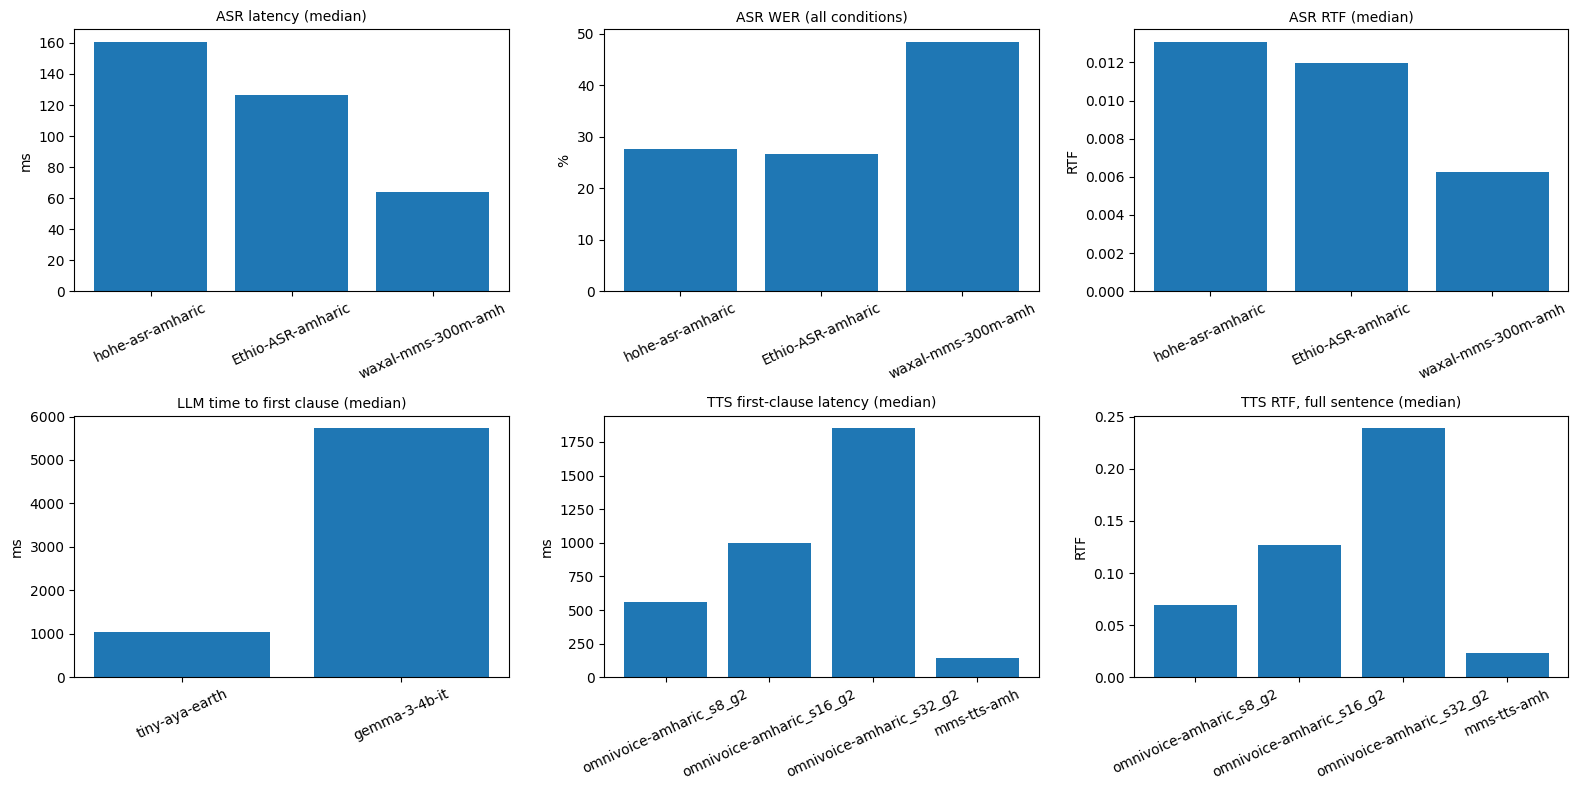

In [26]:
def bar(ax, labels, vals, title, ylabel, errs=None):
    ax.bar(labels, vals, yerr=errs, capsize=3); ax.set_title(title, fontsize=10); ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=25)

fig, axs = plt.subplots(2, 3, figsize=(16, 8))
if "ASR_SUMMARY" in globals():
    s = ASR_SUMMARY
    bar(axs[0, 0], s.index, s.lat_median_ms, "ASR latency (median)", "ms")
    bar(axs[0, 1], s.index, s.wer * 100, "ASR WER (all conditions)", "%")
    bar(axs[0, 2], s.index, s.rtf_median, "ASR RTF (median)", "RTF")
if "LLM_SUMMARY" in globals():
    s = LLM_SUMMARY
    bar(axs[1, 0], s.index, s.first_clause_median_ms, "LLM time to first clause (median)", "ms")
if "TTS_SUMMARY" in globals():
    s = TTS_SUMMARY
    bar(axs[1, 1], s.index, s.first_clause_median_ms, "TTS first-clause latency (median)", "ms")
    bar(axs[1, 2], s.index, s.rtf_full_median, "TTS RTF, full sentence (median)", "RTF")
plt.tight_layout(); plt.savefig(OUT_DIR/"benchmark_charts.png", dpi=150); plt.show()

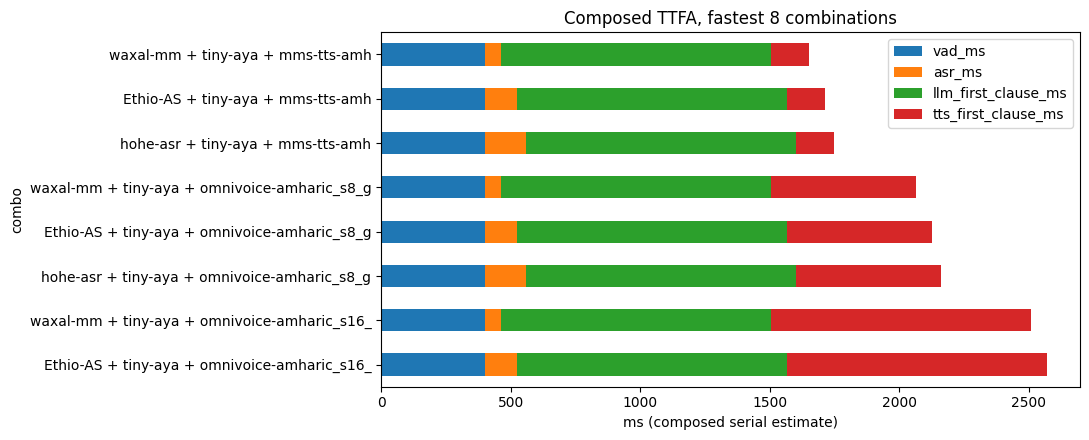

In [27]:
if "COMPOSED" in globals() and len(COMPOSED):
    top = COMPOSED.head(8).copy()
    top["combo"] = top.asr.str[:8] + " + " + top.llm.str[:8] + " + " + top.tts.str[:22]
    parts = top[["vad_ms", "asr_ms", "llm_first_clause_ms", "tts_first_clause_ms"]]
    ax = parts.set_index(top.combo).plot(kind="barh", stacked=True, figsize=(11, 4.5))
    ax.set_xlabel("ms (composed serial estimate)"); ax.set_title("Composed TTFA, fastest 8 combinations")
    ax.invert_yaxis(); plt.tight_layout(); plt.savefig(OUT_DIR/"composed_ttfa.png", dpi=150); plt.show()

## 10. Export and requirements checklist

Everything is written to `results/` (CSV per table, the charts, the rating sheets, saved audio and an `environment.json` with GPU and library versions). The archive is what the team should attach to the Week 6 write-up.

Coverage of the Week 6 brief:

| Brief requirement | Where it is measured |
|---|---|
| ASR WER, CER | Section 5 summary and per-condition tables |
| ASR RTF and time to useful output | Section 5 (`rtf_median`, `lat_median_ms`), plus length scaling |
| ASR names, numbers, code-switching, speaking styles, noise | Section 5 per-condition table, driven by the `condition` column of your manifest |
| LLM generation speed, time to first useful output, total latency | Section 6 (`decode_tps`, `first_clause_ms`, `total_ms`) |
| LLM Amharic understanding | Section 6.1 Belebele accuracy with confidence interval |
| LLM relevance, imperfect ASR text, spoken brevity | Section 6 rating sheet, Section 6.2 robustness pairs, `noisy_asr` prompts, word counts and digit leakage |
| TTS time to first playable audio, total latency, RTF | Section 7 (`first_clause_median_ms`, `full_median_ms`, `rtf_*`) |
| TTS pronunciation, naturalness, names, numbers, mixed text | Section 7 listening sheet and round-trip CER by category |
| Resource consumption for every stage | Load time, peak VRAM, GPU utilization in every summary |
| Documented end-to-end baseline TTFA | Section 8.2 |
| Bottleneck identification | Section 8 stage columns and the stacked chart |

In [28]:
def save(name, obj):
    if obj is not None and len(obj): obj.to_csv(OUT_DIR / f"{name}.csv")

for name, obj in [("asr_summary", globals().get("ASR_SUMMARY")), ("asr_by_condition", globals().get("ASR_BY_COND")),
                  ("asr_all_clips", globals().get("ASR_ALL")),
                  ("asr_length_scaling", pd.concat(ASR_SCALING) if ASR_SCALING else None),
                  ("llm_summary", globals().get("LLM_SUMMARY")), ("llm_all_replies", globals().get("LLM_ALL")),
                  ("tokenizer_efficiency", globals().get("TOKENIZER_EFF")),
                  ("llm_belebele", globals().get("BELEBELE_SUMMARY")), ("llm_asr_robustness", globals().get("LLM_ROBUST")),
                  ("tts_summary", globals().get("TTS_SUMMARY")), ("tts_all", globals().get("TTS_ALL")),
                  ("tts_roundtrip", globals().get("ROUNDTRIP")), ("composed_ttfa", globals().get("COMPOSED")),
                  ("e2e_baseline", E2E_DF)]:
    save(name, obj)
(OUT_DIR / "environment.json").write_text(json.dumps(dict(ENV=ENV, e2e=E2E_META), indent=2, default=str))
shutil.make_archive("week6_benchmark_results", "zip", OUT_DIR)
print("saved:", sorted(p.name for p in OUT_DIR.iterdir()))
try:
    from google.colab import files
    files.download("week6_benchmark_results.zip")
except Exception:
    print("Archive: week6_benchmark_results.zip")

saved: ['asr_all_clips.csv', 'asr_by_condition.csv', 'asr_length_scaling.csv', 'asr_summary.csv', 'benchmark_charts.png', 'composed_ttfa.csv', 'composed_ttfa.png', 'e2e_baseline.csv', 'environment.json', 'llm_all_replies.csv', 'llm_asr_robustness.csv', 'llm_asr_robustness_sheet.csv', 'llm_belebele.csv', 'llm_rating_sheet.csv', 'llm_summary.csv', 'tokenizer_efficiency.csv', 'tts_all.csv', 'tts_listening_sheet.csv', 'tts_roundtrip.csv', 'tts_samples', 'tts_summary.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Reading the results

- **Trust measured values over the report's estimates.** Replace every `est.` value in the Week 6 write-up with the medians and p90 values from here.
- **Compare quality only within one test set.** WER and CER from these tables use one normalization and your sampled clips, so they are not directly comparable with numbers on model cards, even when both use FLEURS. Compare models against each other, and report the `fleurs_*` rows separately from your own clips.
- **Read Belebele with its interval.** With 200 questions the interval is about 7 points either way. A gap smaller than that is not a ranking.
- **Check the fp16 flag before using Gemma numbers.** A failed sanity check invalidates its latency and quality rows.
- **The TTS decision needs the listening sheet.** OmniVoice was selected on the quality constraint. The round-trip CER and blind ratings are what confirm or overturn that, and the composed TTFA shows what it costs.
- **Decide the TTFA target now.** With the measured baseline in Section 8.2, the team can set a numeric target and judge each Week 7 change against it.
- **Not covered here (Week 7 and final evaluation):** concurrency and load tests, `torch.compile`, quantization, prefix caching, streaming or overlapped stages, and evaluation on fully unseen speakers. This notebook gives the baseline those experiments are measured against.